#1. Загрузка данных

Рекомендуется запускать данный ноутбук из директории репозитория, содержащей models. Установка нужных библиотек:
```
>>> ls -a
.  ..  experiments.ipynb  .git  .gitignore  models  README.md  requirements.txt
>>> pip install -r requirements.txt
```

В качестве набора данных будем рассматривать KION_DATASET. Я выбрал его по причине интереса рек. систем в кино, а также русскоязычности данного датасета: https://github.com/irsafilo/KION_DATASET/tree/main.

В data/original содержатся таблицы users.csv, items.csv с описаниями пользователей и товаров, соответственно. Таблица взаимодействий лежит в interactions.csv.zip. Все это загружается и распаковывается через библиотеку pandas.

In [1]:
import pandas as pd

base = "https://raw.githubusercontent.com/irsafilo/KION_DATASET/main"

items = pd.read_csv(f"{base}/data_original/items.csv", index_col='item_id')
users = pd.read_csv(f"{base}/data_original/users.csv", index_col='user_id')

In [2]:
users

,age,income,sex,kids_flg
user_id,,,,
973171,age_25_34,income_60_90,М,1
962099,age_18_24,income_20_40,М,0
1047345,age_45_54,income_40_60,Ж,0
721985,age_45_54,income_20_40,Ж,0
704055,age_35_44,income_60_90,Ж,0
...,...,...,...,...
339025,age_65_inf,income_0_20,Ж,0
983617,age_18_24,income_20_40,Ж,1
251008,NaN,NaN,NaN,0


In [3]:
items

,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
item_id,,,,,,,,,,,,,
10711,film,Поговори с ней,Hable con ella,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,NaN,16.0,NaN,Педро Альмодовар,"Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Мелодрама легендарного Педро Альмодовара «Пого...,"Поговори, ней, 2002, Испания, друзья, любовь, ..."
2508,film,Голые перцы,Search Party,2014.0,"зарубежные, приключения, комедии",США,NaN,16.0,NaN,Скот Армстронг,"Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Уморительная современная комедия на популярную...,"Голые, перцы, 2014, США, друзья, свадьбы, прео..."
10716,film,Тактическая сила,Tactical Force,2011.0,"криминал, зарубежные, триллеры, боевики, комедии",Канада,NaN,16.0,NaN,Адам П. Калтраро,"Адриан Холмс, Даррен Шалави, Джерри Вассерман,...",Профессиональный рестлер Стив Остин («Все или ...,"Тактическая, сила, 2011, Канада, бандиты, ганг..."
7868,film,45 лет,45 Years,2015.0,"драмы, зарубежные, мелодрамы",Великобритания,NaN,16.0,NaN,Эндрю Хэй,"Александра Риддлстон-Барретт, Джеральдин Джейм...","Шарлотта Рэмплинг, Том Кортни, Джеральдин Джей...","45, лет, 2015, Великобритания, брак, жизнь, лю..."
16268,film,Все решает мгновение,NaN,1978.0,"драмы, спорт, советские, мелодрамы",СССР,NaN,12.0,Ленфильм,Виктор Садовский,"Александр Абдулов, Александр Демьяненко, Алекс...",Расчетливая чаровница из советского кинохита «...,"Все, решает, мгновение, 1978, СССР, сильные, ж..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6443,series,Полярный круг,Arctic Circle,2018.0,"драмы, триллеры, криминал","Финляндия, Германия",NaN,16.0,NaN,Ханну Салонен,"Иина Куустонен, Максимилиан Брюкнер, Пихла Вии...","Во время погони за браконьерами по лесу, сотру...","убийство, вирус, расследование преступления, н..."
2367,series,Надежда,NaN,2020.0,"драмы, боевики",Россия,0.0,18.0,NaN,Елена Хазанова,"Виктория Исакова, Александр Кузьмин, Алексей М...",Оригинальный киносериал от создателей «Бывших»...,"Надежда, 2020, Россия"
10632,series,Сговор,Hassel,2017.0,"драмы, триллеры, криминал",Россия,0.0,18.0,NaN,"Эшреф Рейбрук, Амир Камдин, Эрик Эгер","Ола Рапас, Алиетт Офейм, Уильма Лиден, Шанти Р...",Криминальная драма по мотивам романов о шведск...,"Сговор, 2017, Россия"


In [4]:
url = f"{base}/interactions.csv.zip"
interactions = pd.read_csv(url, compression="zip")

In [5]:
interactions

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250.0,72.0
1,699317,1659,2021-05-29,8317.0,100.0
2,656683,7107,2021-05-09,10.0,0.0
3,864613,7638,2021-07-05,14483.0,100.0
4,964868,9506,2021-04-30,6725.0,100.0
...,...,...,...,...,...
1594782,63645,16373,2021-04-20,30964.0,100.0
1594783,90242,15739,2021-07-27,12265.0,100.0
1594784,32937,10954,2021-05-13,71.0,1.0
1594785,311112,4151,2021-07-06,1480.0,13.0


У пользователей помимо user_id несколько полей:
- age - возраст в формате "age_{min}_{max}", где диапозон [min,max] в полных годах.
- income - поле дохода в формате "income_{min}_{max}", где диапозон [min,max] в тысячах рублей.
- sex - пол пользователя (М или Ж).
- kids_flg - флаг (0 или 1) детской подписки.

У товаров полей гораздо больше:
- content_type - тип контента (film или series)
- title - название (видимо, локализованное на рус. язык)
- title_orig - оригинальное название
- release_year - год выпуска
- genres - список жанров
- countries - список стран-производителей
- for_kids - флаг детского фильма/сериала
- age_rating - возрастной рейтинг в формате вещ. числа (например, 12.0, 18.0)
- studios - список студий-производителей
- directors - список режиссеров
- actors - список ведущих актеров
- description - текстовое описание фильма
- keywords - список ключевых слов и тегов в дополнение к описанию

Каждое взаимодействие помимо полей (user_id, item_id) характеризуется полями:
- last_watch_dt - дата последнего просмотра (к сожалению, даты начала просмотра нет)
- total_dur - длительность просмотра (в сек.)
- watched_pct - сколько посмотрел (в процентах)

Отметим, что как такого explicit feedback у нас нет. Тем не менее, если пользователь смотрел слишком мало (случайно включил, либо прекратил просмотр довольно рано), то такой товар вряд ли можно назвать релевантным.

В связи с тем, что длительность может быть разной (есть, возможно, короткометражки, также серии сериалов могут длиться недолго), то порог total_dur не стоит брать большим - возьмем 10 минут (600 секунд). В противном случае, если взаимодействие есть в таблице, то соответ. товар считается нерелевантным (пользователей посмотрел слишком мало и не продолжил просмотр).

Реелевантность вероятно также связана качественно с процентом просмотра, однако фильмы обладают разной длительностью (бывают и фильмы по 3-4 часа), а с сериалами проблема еще сложнее: пользователю действительно могли приглянуться первые сезоны или серии, они действительно ему нравятся и релевантны, однако дальше он мог просто не захотеть смотреть. С учетом этого, для простоты не будем рассматривать watched_pct как критерий релевантности.

В исходном виде данных достаточно много: 1.6M взаимодействий, 800K пользователей и 16K товаров. Для начала необходимо взять подвыборку. Определение релевантных товаров, а также взятие подвыборки и деление на train/test/split будет происходить в след. разделах согласно заданию.

#2. EDA

In [6]:
print(f"Дубликатов взаимодействий: {interactions.duplicated().sum()}")
print(f"Дубликатов пользователей: {users.duplicated().sum()}")
print(f"Дубликатов товаров: {items.duplicated().sum()}")

Дубликатов взаимодействий: 0
Дубликатов пользователей: 839960
Дубликатов товаров: 0


Дубликаты пользователей возникают из-за того, что полей мало и у них мало различных значений (пол, доход итд.)

In [7]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

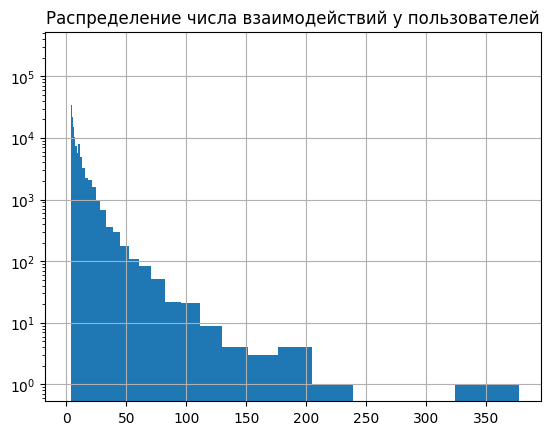

In [8]:
counts = interactions.groupby('user_id')['item_id'].nunique()
plt.hist(counts, bins=np.geomspace(counts.min(),
                           counts.max(), 40))
plt.yscale('log')
plt.title('Распределение числа взаимодействий у пользователей')
plt.grid()
plt.show()

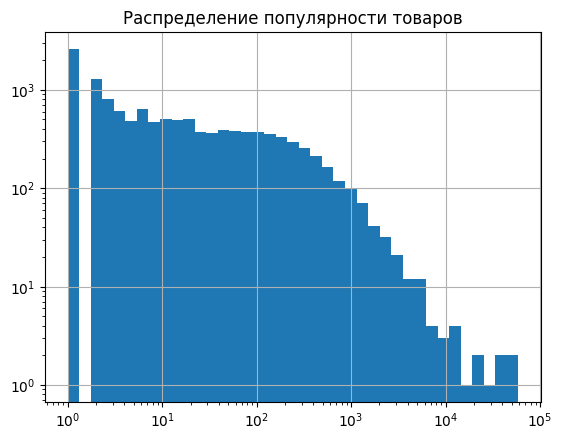

In [9]:
counts = interactions.groupby('item_id')['user_id'].nunique()
plt.hist(counts, bins=np.geomspace(counts.min(),
                           counts.max(), 40))
plt.yscale('log')
plt.xscale('log')
plt.title('Распределение популярности товаров')
plt.grid()
plt.show()

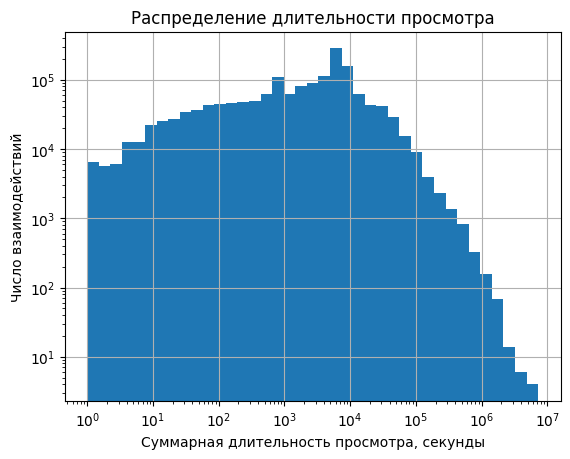

In [10]:
plt.hist(interactions['total_dur'],
         bins=np.geomspace(interactions['total_dur'].min(),
                           interactions['total_dur'].max(), 40))
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Суммарная длительность просмотра, секунды")
plt.ylabel("Число взаимодействий")
plt.title("Распределение длительности просмотра")
plt.grid()
plt.show()

Самые популярные товары:

In [11]:
popular = interactions.groupby("item_id")["user_id"].nunique().nlargest(10)
items.loc[popular.index].assign(n_users=popular)

,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords,n_users
item_id,,,,,,,,,,,,,,
10440,series,Хрустальный,Khrustal'nyy,2021.0,"триллеры, детективы",Россия,NaN,18.0,NaN,Душан Глигоров,"Антон Васильев, Николай Шрайбер, Екатерина Оль...",Сергей Смирнов — один из лучших «охотников на ...,"хруст, хрусталь, хруста, хрус, полицейский, пе...",59133
15297,series,Клиника счастья,Klinika schast'ya,2021.0,"драмы, мелодрамы",Россия,NaN,18.0,NaN,Александр Кириенко,"Дарья Мороз, Анатолий Белый, Данил Акутин, Мар...","Успешный сексолог Алена уверена, что нашла фор...","Клиника счастья, Клиника, Счастье, Клиника сча...",56298
9728,film,Гнев человеческий,Wrath of Man,2021.0,"боевики, триллеры","Великобритания, США",NaN,18.0,NaN,Гай Ричи,"Джейсон Стэйтем, Холт МакКэллани, Джеффри Доно...",Грузовики лос-анджелесской инкассаторской комп...,"ограбление, криминальный авторитет, месть, пер...",38758
13865,film,Девятаев,V2. Escape from Hell,2021.0,"драмы, военные, приключения",Россия,NaN,12.0,NaN,Тимур Бекмамбетов,"Павел Прилучный, Павел Чинарёв, Тимофей Трибун...",Военно-исторический блокбастер от режиссёров Т...,"Девятаев, Девятаева, Девят, Девя, Девята, Девя...",35232
4151,series,Секреты семейной жизни,NaN,2021.0,комедии,Россия,NaN,18.0,NaN,Шота Гамисония,"Петр Скворцов, Алена Михайлова, Федор Лавров, ...",У Никиты и Полины всё начиналось прекрасно: об...,"брызги крови, кровь, жестокое обращение с живо...",26814
3734,film,Прабабушка легкого поведения,Prababushka lyogkogo povedeniya,2021.0,комедии,Россия,NaN,16.0,NaN,Марюс Вайсберг,"Александр Ревва, Глюкоза, Дмитрий Нагиев, Миха...","1980 год, вся страна следит за событиями моско...",", 2021, россия, прабабушка, легкого, поведения",21672
2657,series,Подслушано,Podslushano,2021.0,"драмы, триллеры",Россия,NaN,16.0,NaN,Илья Куликов,"Александр Hовиков, Валентина Ляпина, Никита Па...",Смотри:- как кино- как сериалПодростковый псих...,"подслушано, подслушано в контакте, социальная ...",19985
4880,series,Афера,Afera,2021.0,комедии,Россия,NaN,18.0,NaN,Михаил Старчак,"Сергей Степин, Игорь Царегородцев, Татьяна Лял...","Смотри:- как кино- как сериалКарантин окончен,...","Афера, Аферисты, Карантин, Пандемия, Карантин ...",16020
142,film,Маша,Masha,2020.0,"драмы, триллеры",Россия,NaN,16.0,NaN,Анастасия Пальчикова,"Максим Суханов, Аня Чиповская, Полина Гухман, ...",13-летняя Маша растёт между боксёрским рингом ...,"Фильм Маша, Маша фильм 2021, Смотреть фильм Ма...",13179


Можно заметить, число пользователей с данным числом взаимодействий довольно быстро падает с ростом числа - то есть основная масса пользователей не очень активна (единицы просмтров либо пару десятков), а очень активных сотни.

При этом основная масса товаров имеет десятки или сотни просмотров. Тясячи и десятки тысяч только у пары сотен товаров.

Еще интереснее распределение длительности просмотра в взаимодействиях: с ростом длительности до десяток тысяч секунд (около пары часов) пользователей становится только больше, при этом скорость роста не большая: довольно много уделяет как мало, так и много времени выбранным товарам. Видно, что десятки тысяч взаимодействий окажутся нерелевантными согласно нашей постановки: в них фильмы смотрели слишком недолго, однако основная масса взаимодействий сохранится. При этом потом идет резкое падение числа взаимоедйствий с ростом длительности (уже десятки и сотни часов просмотра).

In [12]:
for feature in users.columns:
    print(feature)
    print(f"{users[feature].unique().tolist()}")
    print(f"Число пропусков: {users[feature].isna().sum().item()}")
    print()

age
['age_25_34', 'age_18_24', 'age_45_54', 'age_35_44', nan, 'age_55_64', 'age_65_inf']
Число пропусков: 14095

income
['income_60_90', 'income_20_40', 'income_40_60', 'income_0_20', nan, 'income_90_150', 'income_150_inf']
Число пропусков: 14776

sex
['М', 'Ж', nan]
Число пропусков: 13831

kids_flg
[1, 0]
Число пропусков: 0



In [13]:
user_cat = ['age', 'income', 'sex', 'kids_flg']

In [14]:
for feature in items.columns:
    print(feature)
    values = items[feature].unique().tolist()
    print(f"Число значений: {len(values)}")
    if len(values) < 10:
        print(f"{items[feature].unique().tolist()}")
    print(f"Число пропусков: {items[feature].isna().sum().item()}")
    print()

content_type
Число значений: 2
['film', 'series']
Число пропусков: 0

title
Число значений: 15293
Число пропусков: 0

title_orig
Число значений: 10576
Число пропусков: 4745

release_year
Число значений: 106
Число пропусков: 98

genres
Число значений: 2771
Число пропусков: 0

countries
Число значений: 688
Число пропусков: 37

for_kids
Число значений: 3
[nan, 0.0, 1.0]
Число пропусков: 15397

age_rating
Число значений: 7
[16.0, 12.0, 6.0, 18.0, 0.0, 21.0, nan]
Число пропусков: 2

studios
Число значений: 39
Число пропусков: 14898

directors
Число значений: 7974
Число пропусков: 1509

actors
Число значений: 12997
Число пропусков: 2619

description
Число значений: 15620
Число пропусков: 2

keywords
Число значений: 15493
Число пропусков: 423



In [15]:
items['release_year'].unique()

array([2002., 2014., 2011., 2015., 1978., 1960., 2016., 2018., 2013.,
       1981., 1987., 2019., 2017., 1986., 2020., 2006., 2007., 1975.,
       2010., 2012., 1999., 1976., 1992., 1994., 1991., 1968., 1993.,
       2004., 2003., 2001., 2009., 2008., 2000., 1996., 1954., 2021.,
       1997.,   nan, 1974., 2005., 1990., 1966., 1982., 1985., 1955.,
       1989., 1939., 1961., 1935., 1995., 1984., 1980., 1988., 1959.,
       1963., 1962., 1958., 1971., 1972., 1969., 1979., 1970., 1998.,
       1943., 1942., 1977., 1983., 1967., 1951., 1965., 1948., 1964.,
       1897., 1953., 1941., 1952., 1938., 1931., 1920., 1973., 1947.,
       1940., 1946., 1949., 1950., 1956., 1957., 1932., 1921., 1917.,
       1918., 1937., 1926., 1933., 1945., 1934., 1936., 1944., 1929.,
       1927., 1928., 1916., 1924., 1930., 1925., 1922.])

In [16]:
def multi(column):
    res = set()
    for el in column.dropna().tolist():
        res |= set(el.split(', '))
    return list(res)

item_multi_candidates = ['genres', 'directors', 'studios', 'actors', 'keywords', 'countries']
for feature in item_multi_candidates:
    print(feature)
    values = multi(items[feature])
    print(f"Число значений: {len(values)}")
    if len(values) < 10:
        print(f"{items[feature].unique().tolist()}")
    print(f"Число пропусков: {items[feature].isna().sum().item()}")
    print()

genres
Число значений: 95
Число пропусков: 0

directors
Число значений: 8839
Число пропусков: 1509

studios
Число значений: 32
Число пропусков: 14898

actors
Число значений: 61887
Число пропусков: 2619

keywords
Число значений: 43692
Число пропусков: 423

countries
Число значений: 91
Число пропусков: 37



In [17]:
item_cat = ["content_type", "for_kids", "age_rating"]
item_num = ["release_year"]
item_multi = ['genres', 'studios', 'countries']

In [18]:
def plot_feature(col, xlabel, ylabel, title):
    col.fillna("unknown").value_counts().sort_index().plot.bar()

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.grid()
    plt.show()

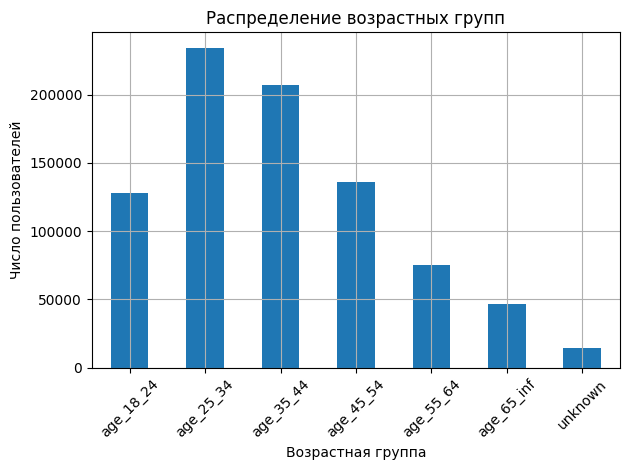

In [19]:
plot_feature(users["age"], "Возрастная группа", "Число пользователей", "Распределение возрастных групп")

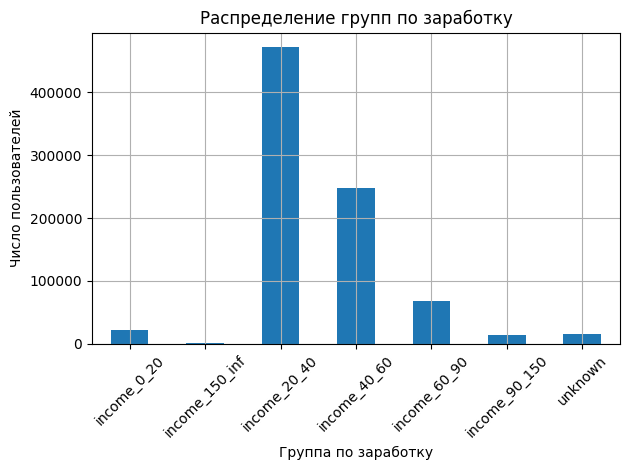

In [20]:
plot_feature(users["income"], "Группа по заработку", "Число пользователей", "Распределение групп по заработку")

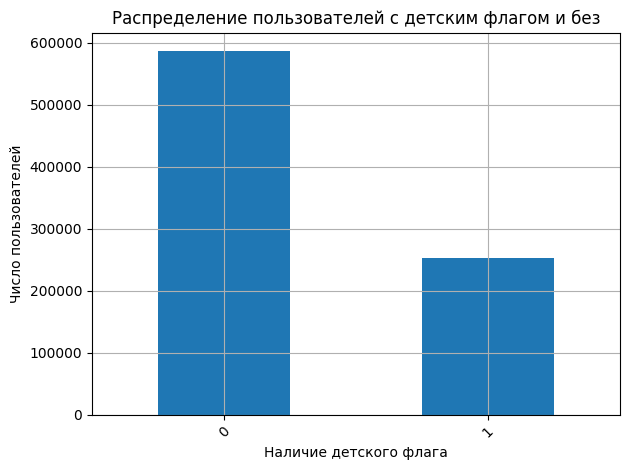

In [21]:
plot_feature(users["kids_flg"], "Наличие детского флага",
             "Число пользователей", "Распределение пользователей с детским флагом и без")

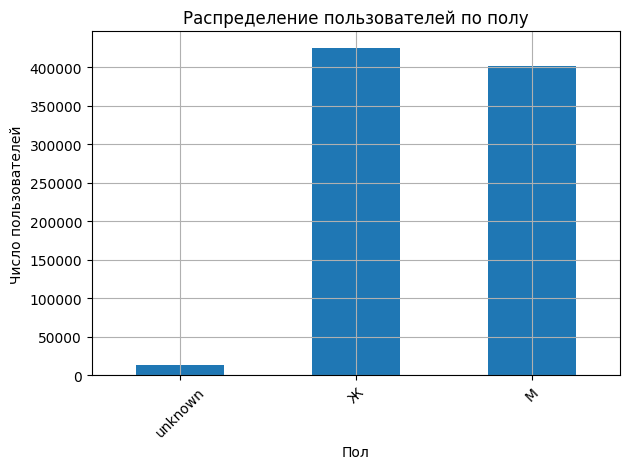

In [22]:
plot_feature(users["sex"], "Пол",
             "Число пользователей", "Распределение пользователей по полу")

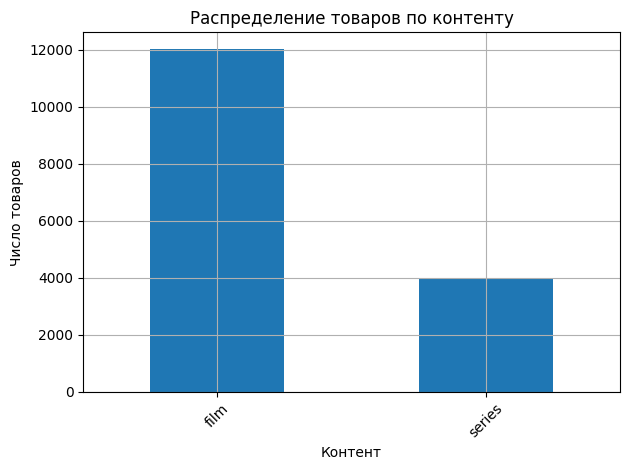

In [23]:
plot_feature(items["content_type"], "Контент",
             "Число товаров", "Распределение товаров по контенту")

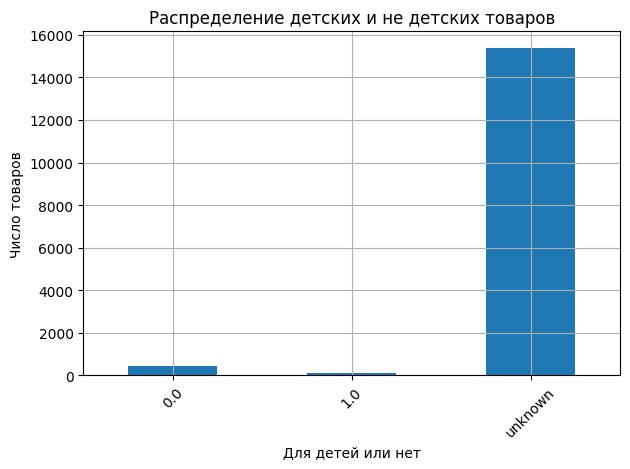

In [24]:
plot_feature(items["for_kids"].astype("string"), "Для детей или нет",
             "Число товаров", "Распределение детских и не детских товаров")

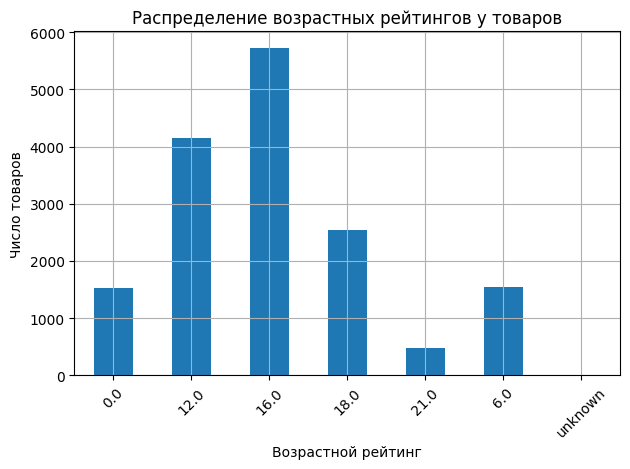

In [25]:
plot_feature(items["age_rating"].astype("string"), "Возрастной рейтинг",
             "Число товаров", "Распределение возрастных рейтингов у товаров")

In [26]:
interactions = interactions.copy()
interactions['last_watch_dt'] = pd.to_datetime(
    interactions['last_watch_dt'], format="%Y-%m-%d", errors="coerce",
)
interactions['last_watch_dt'].min(), interactions['last_watch_dt'].max()

(Timestamp('2021-03-13 00:00:00'), Timestamp('2021-08-22 00:00:00'))

In [27]:
print(f"Пропусков: {interactions['last_watch_dt'].isna().sum().item()}")

Пропусков: 1


Заметим, что данные обладают высокой разреженностью: 1.6 млн на 800К и 16К товаров. То есть заполнено примерно 1/8000 часть от всех теоретически возможных взаимодействий. С вычислительной точки зрения это для нас выгодно, однако это может и свидетельствовать о низкой активности пользователей (что отчасти подтверждает графиком выше).

Заметим также , что признаки пользователей (age, income, sex, kids_flg) категориальны. Причем пропусков достаточно много, однако гораздо меньше общего числа пользователей, что приемлемо для нас. Однако использование их на входе моделей довольно спорно. Дело в том, что возраст, доход и детский флаг в теории могли бы обновляться, либо быть не сразу заполнены (отсюда unknown), что могло бы привести к переобучению. Тем не менее, так как пропусков заведомо меньше, на свой страх и риск, считаем, что эти данные заполняются в начале и не меняются. Кроме того, если посмотреть на last_watch_dt, можно заметить, там всего лишь 1 пропуск (можно спокойно удалять данное взаимодействие), при этом период наблюдений относительно недолгий (около полугода), что снижает вероятность изменений мета-данных пользователей.

С точки зрения товаров с пропусками ситуацию аналогичная, хотя в ряде случаев их довольно много (actors, title_orig), а в  for_kid, sudios их - подавляющее большинство. Тем не менее, информацию о студиях и детских фильмах все же может быть полезна. При этом названия фильмов, их описания и ключевые слова не будем использовать на входе моделей (так как не применяем языковые модели для анализа строковых данных). Категориальные признаки - content_type, for_kids, age_ratings (здесь, как и для признаков users пропуск будем счиать равноценным нулевому one-hot вектору). Численный - release_year, чтобы учитывать близость между годами (пропуски стандартно заменим медианным значением). Мульти-категориальные (в поле записаны неск. категорий) - countries, studios, genres (соответствуют one-hot векторы с неск. единицами).

При это признаки взаимодействий вряд ли удастся использования в моделях, так как они появляются уже после сбора информации о взаимодействии до рекомендации. Однако last_watch_dt можно использовать в обучении моделей типа TimeSVD.

Теперь начнем проводить фильтрацию. Обработку годов выпуска фильмов сделаем для корректности уже после окончательного формирования обучающей выборки и прочих. Заранее оговоримся, что выбранную подвыборку будем делить по времени, так как есть last_watch_dt.

Для рациональной оценки способностей обучаемых рек. систем будем рассматривать только активных пользователей (остальные при разбиении выборки на train/valid/test по времени либо только будут участвовать в обучении с не большим числом полезных связей/признаков, либо и вовсе с высокой вероятностью попадут только в val/test с проблемой cold start, из-за которой мы вынуждены будем их не учитывать в результатах валидации). Для наличия достаточной информации для обучения и валидации рек. системы, будем рассматривать только пользователей с не менее 10 взаимоедйствий. Так как активность итак мала по выборке, будем в качестве активности считать и короткие взаимодействия (короткие просмотры меньше 10 минут, нерелевантные, вообще говоря). Для остальной массы наша рек. система в реальной жизни бы рекомендовала просто наиболее популряные фильмы в каталоге из-за недостатка информации и подверженности холодному старту моделей в данном ДЗ.

In [28]:
interactions = interactions.dropna(subset=["last_watch_dt"])

In [29]:
activity = interactions.groupby("user_id")["item_id"].nunique()
eligible = activity[activity >= 10].index
users = users.loc[users.index.isin(eligible)].copy()
interactions = interactions[interactions['user_id'].isin(users.index)]
items = items[items.index.isin(interactions['item_id'].unique())]

print(f"Пользователей: {len(users)}")
print(f"Товаров: {len(items)}")
print(f"Взаимодействий: {len(interactions)}")

Пользователей: 20380
Товаров: 9991
Взаимодействий: 330681


#3. Split

Разбиваем по времени, а точнее - last_watch_dt. Считаем, что данное поле фиксирует факт завершения просмотра в контексте всего времени наблюдения.

In [30]:
SEED = 42
SPLIT = (0.7, 0.15, 0.15)
assert sum(SPLIT) == 1
valid_start, test_start = interactions['last_watch_dt'].quantile([SPLIT[0], 1 - SPLIT[2]]).dt.normalize()
print(valid_start, test_start)

2021-07-20 00:00:00 2021-08-05 00:00:00


In [31]:
train = interactions[interactions['last_watch_dt'] < valid_start]
valid = interactions[(interactions['last_watch_dt'] < test_start) & (interactions['last_watch_dt'] >= valid_start)]
test = interactions[(interactions['last_watch_dt'] >= test_start)]
print("Train / validation / test:", len(train), len(valid), len(test))

Train / validation / test: 230959 48226 51496


Теперь, оставим только релевантные взаимодействия, как мы условились ранее, однако для обучения и подбора гиперпараметров на валид. выборке сохраним и короткие взаимодействия:

In [32]:
train_seen = train.copy()
valid_seen = valid.copy()

MIN_DUR = 600
train = train[train.total_dur >= MIN_DUR].copy()
valid = valid[valid.total_dur >= MIN_DUR].copy()
test = test[test.total_dur >= MIN_DUR].copy()

In [33]:
print("Train / validation / test:", len(train), len(valid), len(test))

Train / validation / test: 171946 35690 36909


На валидации и тесте рассматриваем только не новые объекты, которые хоть раз были в обучении, так как имеющиеся методы без какой-либо информации вряд ли качественно будут ранжировать товары:

In [34]:
train_users = train["user_id"].unique()
valid = valid[valid.user_id.isin(train_users)].copy()
test = test[test.user_id.isin(train_users)].copy()
print("Train / validation / test:", len(train), len(valid), len(test))

train_items = train["item_id"].unique()
valid = valid[valid.item_id.isin(train_items)].copy()
test = test[test.item_id.isin(train_items)].copy()
print("Train / validation / test:", len(train), len(valid), len(test))

Train / validation / test: 171946 29704 27489
Train / validation / test: 171946 28374 24554


Создаем разреженные матрицы всех и только долгих взаимодействий по обучающей выборке:

In [35]:
from scipy import sparse

user_to_idx = {uid: i for i, uid in enumerate(users.index)}
item_to_idx = {iid: i for i, iid in enumerate(items.index)}

def make_matrix(frame):
    result = sparse.csr_matrix(
        (np.ones(len(frame)),
         (frame.user_id.map(user_to_idx), frame.item_id.map(item_to_idx))),
        shape=(len(users), len(items)),
    )
    result.data[:] = 1
    return result

matrix = make_matrix(train)
matrix_train = matrix
seen_train = make_matrix(train_seen)

Число пользователей на обучении:

In [36]:
activity = train.groupby("user_id")["item_id"].nunique()
eligible = activity[activity > 0].index
len(eligible)

18564

Производим нормализацию признака года выпуска фильма по обуч. выборке, а пропуски заполняем медианой:

In [37]:
items = items.copy()
year = items["release_year"]
train_year = year.loc[year.index.isin(train["item_id"])]

items["year_missing"] = year.isna().astype(int)
filled = year.fillna(train_year.median())
reference = filled.loc[filled.index.isin(train["item_id"])]

items["release_year"] = (filled - reference.mean()) / reference.std()

На валидации и тесте будем оставлять только взаимодействия, которых не было в обучении (то есть даже короткие и нерелевантные уже не учавствуют в рекомендациях):

In [38]:
from tqdm.auto import tqdm

def filter(valid, matrix):
    ground_truth = {}
    for user_id, group in tqdm(valid.groupby("user_id")):
        user = user_to_idx[user_id]
        items = group["item_id"].map(item_to_idx).unique()
        items = np.setdiff1d(items, matrix[user].indices)
        if len(items):
            ground_truth[user] = items
    return ground_truth

In [39]:
valid_gt = filter(valid, seen_train)
len(valid_gt)

  0%|          | 0/10270 [00:00<?, ?it/s]

10270

Функция рекомендации моделью топ-10 товаров для пользователей выборки:

In [40]:
def recommend(model, matrix, ground_truth, k=10):
    candidates = np.flatnonzero(matrix_train.getnnz(axis=0))
    recommendations = {}
    for user in tqdm(ground_truth, leave=False):
        scores = model.predict_score(user)
        available = np.setdiff1d(candidates, matrix[user].indices)
        top = np.argsort(-scores[available], kind="stable")[:k]
        recommendations[user] = available[top]
    return recommendations

#4. Models

Рассматриваются 5 моделей:
1. CF. Выбран вариант Item2Item, так как их гораздо меньше пользователей и на каждый item приходится достаточно много статистики. При вычислении близостей рассматриваются только k ближайших соседей из соображений эффективности работы алгоритма и регуляризации. Рассмотрены 2 метрики близости с учетом того, что нет explicit feedback и есть только рел./не рел. взаимодействия: косинусная (между бинарными векторами релевантности) и мера Жаккарда, которые дополнительно (согласно семинарам и лекциям) домножаются на $n_{ij} / (n_{ij} + \lambda)$, где $n_{ij}$ - число общих пользователей. Тем самым позволяет давать больший вес парам товаров с общими пользователями.

2. Рассматривается IALS, опять же из-за отсутствия explicit feedback. При это для рел. объектов вес (в соответствии с лекциями) равен 1 + $\alpha$, для отсут. взаимодействий - 1. Для коротких эвристически выбран средний вариант - 1 + 0.5$\alpha$, так как нет полной гарантии, что объект действительно не стоило бы рекомендовать, но все же уверенность выше, чем у неизв. взаимодействий.

3. EASE.

4. FM. Используются помимо user_id, item_id признаки пользователей и товаров, упомянутые выше (см. подробный разбор в разделе EDA). При этом FM решает задачу бинарной классификации: релевантен/не релевантен. В качестве нерелевантных рассматриваются короткие взаимодействия, а также случайно выбираемые из оставшихся отсут. взаимодействий. Причем по аналогии с IALS первым отриц. объектам дается вес 0.5, так как пользователь хотя бы посмотрел товары. Сэмплирование отсут. взаим. ведется, пока для пользователя число полож. и отриц. объектов на обучении не станет примерно одинаковым (если итак достаточно коротких взаим., то сэмплирование не ведется).

5. Используется временная модификация IALS. Чем раньше от нас стоит товар, тем он менее релевантен: поэтому единичные таргеты (матрица p из лекций) в IALS домножаются на множитель $exp\{-(max\_time - last\_watch\_dt)/T\}$, где под $max\_time$ мы будем понимать порог, по которому train отделяется от val, test. Подбор гиперпараметро для модификации будем осуществлять так: берутся лучшие гиперпараметры стандартного ALS, потом идет перебор знаменателя T, определяющего скорость забывания старых взаимодействий.

In [44]:
from models.cf import CF
from models.ials import IALS
from models.ease import EASE
from models.fm import FM
from models.time_ials import TimeIALS

Подготовка мета-признаков для FM:

In [45]:
import torch

def fm_features(interactions):
    dim = len(users) + len(items) + 1
    user_to_idx = {uid: i + 1 for i, uid in enumerate(users.index)}
    item_to_idx = {iid: len(users) + i + 1 for i, iid in enumerate(items.index)}
    names = {}
    for feature in user_cat:
        for el in sorted(users[feature].dropna().unique().tolist()):
            names[f"{feature}::{el}"] = dim
            dim += 1
    for feature in item_cat:
        for el in sorted(items[feature].dropna().unique().tolist()):
            names[f"{feature}::{el}"] = dim
            dim += 1
    for feature in item_num:
        names[feature] = dim
        dim += 1
    for feature in item_multi:
        for el in sorted(multi(items[feature])):
            names[f"{feature}::{el}"] = dim
            dim += 1
    features = []
    for i in tqdm(range(len(interactions))):
        row = interactions.iloc[i]
        user = users.loc[row["user_id"]]
        item = items.loc[row["item_id"]]
        indices = [user_to_idx[row["user_id"]], item_to_idx[row["item_id"]]]
        values = [1.0, 1.0]
        for feature in user_cat:
            key = f"{feature}::{user[feature]}"
            index = names.get(key, 0)
            indices.append(index)
            values.append(float(index != 0))
        for feature in item_cat:
            key = f"{feature}::{item[feature]}"
            if not pd.isna(item[feature]) and key in names:
                indices.append(names[key])
                values.append(1.0)
        for feature in item_num:
            indices.append(names[feature])
            values.append(float(item[feature]))
        for feature in item_multi:
            if not pd.isna(item[feature]):
                for el in sorted(set(item[feature].split(", "))):
                    key = f"{feature}::{el.strip()}"
                    if key in names:
                        indices.append(names[key])
                        values.append(1.0)
        features.append((indices, values))
    return features, names, dim

In [46]:
train_fm, names, dim = fm_features(train)

  0%|          | 0/171946 [00:00<?, ?it/s]

In [47]:
short = train_seen[train_seen.total_dur.lt(MIN_DUR)]
short_matrix = make_matrix(short)
short_fm, _, _ = fm_features(short)

  0%|          | 0/59013 [00:00<?, ?it/s]

Подготовка данных для TimeIALS:

In [48]:
last_time = matrix.copy()

for i in tqdm(range(len(train))):
    row = train.iloc[i]
    user = user_to_idx[row["user_id"]]
    item = item_to_idx[row["item_id"]]
    last_time[user, item] = pd.Timestamp(row["last_watch_dt"]).value / 1e9

  0%|          | 0/171946 [00:00<?, ?it/s]

In [49]:
time = pd.Timestamp(valid_start).value / 1e9

Подбор гиперпараметров будет осуществляться по метрике NDCG@10, так как метрика позволяет учитывать качество ранжирования релевантных объектов и способность выдавать их в топе рекомендаций.

In [50]:
def ndcg(recommendations, ground_truth, k=10):
    values = []
    discount = 1 / np.log2(np.arange(2, k + 2))
    for user, truth in ground_truth.items():
        hits = np.isin(recommendations[user][:k], truth)
        dcg = (hits * discount[:len(hits)]).sum()
        ideal = discount[:min(k, len(truth))].sum()
        values.append(dcg / ideal)
    return np.mean(values)

In [53]:
from itertools import product
classes = {"CF": CF, "IALS": IALS, "EASE": EASE, "FM": FM, "TimeIALS": TimeIALS}
params = {
    "CF": [
        dict(k=k, lambda_=lam, similarity=s)
        for k, lam, s in product(
            (50, 100, 200), (1, 10), ("cosine", "jaccard")
        )
    ],
    "IALS": [
        dict(k=k, num_iters=15, alpha=a, lambda_=lam, seed=SEED)
        for k, a, lam in product((32, 64), (10, 40), (1, 10))
    ],
    "EASE": [
        dict(lambda_=r)
        for r in (1, 10, 100, 500)
    ],
    "FM": [
        dict(
            dim=dim, n_users=len(users), n_items=len(items),
            k=k, lr=lr, weight_decay=wd,
            num_epochs=8, batch_size=1024, seed=SEED,
        )
        for k, lr, wd in product(
            (16, 32), (0.001, 0.01), (1e-5, 1e-3)
        )
    ],
}

In [54]:
import time as tm

K = 10
best_params = {}
best_models = {}
validation_results = []
for name in ("CF", "IALS", "EASE", "FM", "TimeIALS"):
    if name == "TimeIALS":
        params[name] = [
            dict(**best_params["IALS"], time=time, T=days * 86400)
            for days in (7, 30, 90, 180)
        ]
    best_score = -np.inf
    for param in params[name]:
        model = classes[name](**param)
        fit_time = tm.time()
        if name == "TimeIALS":
            model.fit((matrix, last_time), short=short_matrix)
        elif name == "IALS":
            model.fit(matrix, short=short_matrix)
        elif name == "FM":
            model.fit(
                train_fm,
                short=short_fm,
                seen=seen_train,
                user_feature_count=len(user_cat),
            )
        else:
            model.fit(matrix)
        fit_time = tm.time() - fit_time
        inference_time = tm.time()
        recs = recommend(model, seen_train, valid_gt, K)
        inference_time = tm.time() - inference_time
        score = ndcg(recs, valid_gt, K)
        validation_results.append({"model": name, "params": param.copy(),
                                   "NDCG@10": score, "fit_time": fit_time,
                                   "inference_time": inference_time})
        print(name, param, score)
        if score > best_score:
            best_score = score
            best_params[name] = param.copy()
            best_models[name] = model
        else:
            del model

  0%|          | 0/10270 [00:00<?, ?it/s]

CF {'k': 50, 'lambda_': 1, 'similarity': 'cosine'} 0.041120154456885466


  0%|          | 0/10270 [00:00<?, ?it/s]

CF {'k': 50, 'lambda_': 1, 'similarity': 'jaccard'} 0.03840049138393197


  0%|          | 0/10270 [00:00<?, ?it/s]

...

item step:   0%|          | 0/9991 [00:00<?, ?it/s]

user step:   0%|          | 0/20380 [00:00<?, ?it/s]

item step:   0%|          | 0/9991 [00:00<?, ?it/s]

  0%|          | 0/10270 [00:00<?, ?it/s]

TimeIALS {'k': 32, 'num_iters': 15, 'alpha': 10, 'lambda_': 10, 'seed': 42, 'time': 1626739200.0, 'T': 15552000} 0.04018328096918


In [55]:
from IPython.display import display, Markdown

validation_df = pd.DataFrame(validation_results)
validation_df["inference_ms_per_user"] = 1000 * validation_df.inference_time / len(valid_gt)
display(validation_df.sort_values(["model", "NDCG@10"], ascending=[True, False]).round(4))

best_validation = (
    validation_df.sort_values("NDCG@10", ascending=False, kind="stable")
    .drop_duplicates("model").set_index("model")
)
display(best_validation[["params", "NDCG@10", "fit_time", "inference_time",
                         "inference_ms_per_user"]].round(4))

,model,params,NDCG@10,fit_time,inference_time,inference_ms_per_user
10,CF,"{'k': 200, 'lambda_': 10, 'similarity': 'cosine'}",0.0524,1.4261,10.9699,1.0681
6,CF,"{'k': 100, 'lambda_': 10, 'similarity': 'cosine'}",0.0521,1.2708,9.3955,0.9148
2,CF,"{'k': 50, 'lambda_': 10, 'similarity': 'cosine'}",0.0518,1.7826,8.7994,0.8568
11,CF,"{'k': 200, 'lambda_': 10, 'similarity': 'jacca...",0.0473,1.4403,11.0106,1.0721
7,CF,"{'k': 100, 'lambda_': 10, 'similarity': 'jacca...",0.0470,1.6548,8.6393,0.8412
3,CF,"{'k': 50, 'lambda_': 10, 'similarity': 'jaccard'}",0.0465,1.1683,9.4790,0.9230
8,CF,"{'k': 200, 'lambda_': 1, 'similarity': 'cosine'}",0.0448,2.1380,10.4916,1.0216
4,CF,"{'k': 100, 'lambda_': 1, 'similarity': 'cosine'}",0.0428,1.2789,10.1931,0.9925
0,CF,"{'k': 50, 'lambda_': 1, 'similarity': 'cosine'}",0.0411,1.1639,9.5089,0.9259
9,CF,"{'k': 200, 'lambda_': 1, 'similarity': 'jaccard'}",0.0400,2.4978,10.3807,1.0108


,params,NDCG@10,fit_time,inference_time,inference_ms_per_user
model,,,,,
CF,"{'k': 200, 'lambda_': 10, 'similarity': 'cosine'}",0.0524,1.4261,10.9699,1.0681
EASE,{'lambda_': 500},0.0513,114.3379,19.9893,1.9464
FM,"{'dim': 30604, 'n_users': 20380, 'n_items': 99...",0.0492,163.2148,154.0034,14.9955
TimeIALS,"{'k': 32, 'num_iters': 15, 'alpha': 10, 'lambd...",0.0442,199.8676,19.3532,1.8844
IALS,"{'k': 32, 'num_iters': 15, 'alpha': 10, 'lambd...",0.0359,186.8099,22.8885,2.2287


По валидации предварительные выводы следующие:
- Наиболее слабо себя проявил IALS, FM, CF показали лучшие результаты только при определенных гиперпараметрах.
- FM оказался заведомо дороже других по времени инференса из-за дорогих высилений на torch над мета-признаками и отсутствия ГПУ при запуске. Однако IALS (из-за многократных матричных операций) обучается еще дольше. Меньше всего время обучения и инференса у CF, который на валидации выглядит tradeoff между качеством и стоимостью.
- В CF улучшение качество достигается за счет выбора косинусной метрики, а также высокий порог $\lambda$ для множителя. Второе позволяет избегать пар товаров с малым числом общих пользователей (регуляризация). Первое вероятно лучше Jaccard за счет того, что лучше обрабатывает случаи, когда у товаров разная популярность. При этом повышение числа соседей повышает качество незначительно.
- В IALS повышение размерности не повышает качество (возможно, только еще больше ведет к переобучению), альфа также влияет на результаты слабо. Небольшие улучшения достигаются только за счет повышений $\lambda$ и регуляризации.
- В EASE опять же необходима регуляризация для борьбы с переобучением и выделением ключевых связей между объектами.
- В FM повышение параметров k и lr только приводит к переобучению, однако повышение регуляризационного параметра weight decay оптимизатора улучшает качество значительно.
- TimeIALS демонстрирует, что временные таргеты замето улучшают качество IALS - учитываются переменные интересы пользователей в ходе периода сбора данных. Однако необходим оптимальный параметр T (неслишком большой, иначе будет сходство с IALS, и не слишком малый, иначе произойдет зануление таргетов у релевант. взаимодействий).

#5. Test

На тесте для каждой из 5 моделей возьмем самые успешные комбинации гиперпараметров по валид. выборке из прошлого раздела.

In [56]:
seen_test = make_matrix(pd.concat([train_seen, valid_seen]))
test_gt = filter(test, seen_test)
len(test_gt)

  0%|          | 0/9321 [00:00<?, ?it/s]

9321

Как и ранее помимо метрик рекомендательных систем будем рассматривать время обучения и инференса модели на тесте для понимания вычислительной эффективности подходов (наших реализаций). В качестве самих метрик рассмотрим помимо NDCG еще 4 стандартные, дающие нам полезную информацию о характере получившейся модели: Recall@10 (какая доля рел. объектов попадает в топ-10), Precision@10 (какая доля топа релевантна), HitRate@10 (доля пользователей хотя бы с 1 рел. рекомендацией), MRR@10 (насколько высоко эта рел. рекомендация), Coverage@10 ( даже если точность и полнота модели плохи, насколько удается покрыть каталог товара).

In [57]:
def metrics(recommendations, ground_truth, k=10):
    recall, precision, hitrate, mrr = [], [], [], []
    for user, truth in ground_truth.items():
        hits = np.isin(recommendations[user][:k], truth)
        positions = np.flatnonzero(hits) + 1
        recall.append(hits.sum() / len(truth))
        precision.append(hits.sum() / k)
        hitrate.append(float(hits.any()))
        mrr.append(1 / positions[0] if len(positions) else 0)
    return {"NDCG@10": ndcg(recommendations, ground_truth, k),
            "Recall@10": np.mean(recall), "Precision@10": np.mean(precision),
            "HitRate@10": np.mean(hitrate), "MRR@10": np.mean(mrr)}

In [58]:
test_results, test_recommendations = [], {}
for name, model in best_models.items():
    inference_time = tm.time()
    recs = recommend(model, seen_test, test_gt, K)
    inference_time = tm.time() - inference_time
    scores = metrics(recs, test_gt, K)
    recommended_items = {item for top in recs.values() for item in top}
    scores["Coverage@10"] = len(recommended_items) / (matrix.getnnz(axis=0) > 0).sum()
    test_results.append({
        "model": name, "params": best_params[name].copy(),
        "Validation NDCG@10": best_validation.loc[name, "NDCG@10"],
        **scores, "fit_time": best_validation.loc[name, "fit_time"],
        "test_inference_time": inference_time,
        "test_ms_per_user": 1000 * inference_time / len(test_gt)
    })
    test_recommendations[name] = recs
    print(name, scores, f"inference: {inference_time:.2f} s")
comparison = pd.DataFrame(test_results).set_index("model").sort_values("NDCG@10", ascending=False)
display(comparison.round(4))

  0%|          | 0/9321 [00:00<?, ?it/s]

CF {'NDCG@10': np.float64(0.04375689711359429), 'Recall@10': np.float64(0.06542449029049888), 'Precision@10': np.float64(0.01506276150627615), 'HitRate@10': np.float64(0.136144190537496), 'MRR@10': np.float64(0.05658084748042907), 'Coverage@10': np.float64(0.42424242424242425)} inference: 9.81 s


  0%|          | 0/9321 [00:00<?, ?it/s]

IALS {'NDCG@10': np.float64(0.029203982501182613), 'Recall@10': np.float64(0.04494373276706886), 'Precision@10': np.float64(0.011050316489647034), 'HitRate@10': np.float64(0.10202767943353717), 'MRR@10': np.float64(0.038374731575568394), 'Coverage@10': np.float64(0.08673400673400673)} inference: 16.39 s


  0%|          | 0/9321 [00:00<?, ?it/s]

...

  0%|          | 0/9321 [00:00<?, ?it/s]

FM {'NDCG@10': np.float64(0.042236732207476486), 'Recall@10': np.float64(0.06107313909591269), 'Precision@10': np.float64(0.013861173693809679), 'HitRate@10': np.float64(0.1291706898401459), 'MRR@10': np.float64(0.05616439580874727), 'Coverage@10': np.float64(0.0051178451178451176)} inference: 118.84 s


  0%|          | 0/9321 [00:00<?, ?it/s]

TimeIALS {'NDCG@10': np.float64(0.03529404142060336), 'Recall@10': np.float64(0.055438914668610215), 'Precision@10': np.float64(0.012863426670958052), 'HitRate@10': np.float64(0.11876408110717734), 'MRR@10': np.float64(0.0431282068311357), 'Coverage@10': np.float64(0.06707070707070707)} inference: 15.96 s


,params,Validation NDCG@10,NDCG@10,Recall@10,Precision@10,HitRate@10,MRR@10,Coverage@10,fit_time,test_inference_time,test_ms_per_user
model,,,,,,,,,,,
CF,"{'k': 200, 'lambda_': 10, 'similarity': 'cosine'}",0.0524,0.0438,0.0654,0.0151,0.1361,0.0566,0.4242,1.4261,9.8119,1.0527
EASE,{'lambda_': 500},0.0513,0.0427,0.0635,0.0148,0.1345,0.0554,0.1868,114.3379,16.5117,1.7714
FM,"{'dim': 30604, 'n_users': 20380, 'n_items': 99...",0.0492,0.0422,0.0611,0.0139,0.1292,0.0562,0.0051,163.2148,118.8355,12.7492
TimeIALS,"{'k': 32, 'num_iters': 15, 'alpha': 10, 'lambd...",0.0442,0.0353,0.0554,0.0129,0.1188,0.0431,0.0671,199.8676,15.9569,1.7119
IALS,"{'k': 32, 'num_iters': 15, 'alpha': 10, 'lambd...",0.0359,0.0292,0.0449,0.0111,0.1020,0.0384,0.0867,186.8099,16.3892,1.7583


Дополнительно рассмотрим рекомендации для 3 пользователей:

In [59]:
user = int(np.random.default_rng(SEED).choice(list(test_gt)))
raw_user = users.index[user]
print("Пользователь:", raw_user)
recent = pd.concat([train, valid])
recent = recent[recent.user_id == raw_user].sort_values("last_watch_dt").tail(5)
display(recent[["item_id", "last_watch_dt"]].assign(title=recent.item_id.map(items.title)))
rows = []
for name, recs in test_recommendations.items():
    for rank, item in enumerate(recs[user], 1):
        rows.append({"model": name, "rank": rank, "item_id": items.index[item],
                     "title": items.iloc[item].title, "genres": items.iloc[item].genres})
display(pd.DataFrame(rows))

Пользователь: 101076


,item_id,last_watch_dt,title
853113,9363,2021-05-10,Пчёлы делают мёд
656855,8192,2021-05-23,Безумие
357099,14823,2021-05-30,Как приручить дракона 3
841160,12013,2021-06-26,Паранормальный отряд
82840,13109,2021-07-10,Новый парень моей мамы


,model,rank,item_id,title,genres
0,CF,1,15102,Храбрецы (с субтитрами),боевики
1,CF,2,5251,Мисс Пуля,"боевики, драмы, триллеры, криминал"
2,CF,3,14703,Денежная игла,триллеры
3,CF,4,9633,Команда,"драмы, зарубежные, криминал"
4,CF,5,15931,Дело Декабристов,"драмы, исторические, документальное"
5,CF,6,11618,В неведении,"драмы, триллеры"
6,CF,7,8405,Круг избранных,"драмы, зарубежные, триллеры"
7,CF,8,10379,Фотосессия,детективы
8,CF,9,9719,XIII: Заговор,"криминал, детективы, зарубежные, триллеры, бое..."
9,CF,10,137,Неприятность,"драмы, триллеры"


In [60]:
user = int(np.random.default_rng(SEED + 1).choice(list(test_gt)))
raw_user = users.index[user]
print("Пользователь:", raw_user)
recent = pd.concat([train, valid])
recent = recent[recent.user_id == raw_user].sort_values("last_watch_dt").tail(5)
display(recent[["item_id", "last_watch_dt"]].assign(title=recent.item_id.map(items.title)))
rows = []
for name, recs in test_recommendations.items():
    for rank, item in enumerate(recs[user], 1):
        rows.append({"model": name, "rank": rank, "item_id": items.index[item],
                     "title": items.iloc[item].title, "genres": items.iloc[item].genres})
display(pd.DataFrame(rows))

Пользователь: 559532


,item_id,last_watch_dt,title
1196439,561,2021-06-22,План побега
1084741,3734,2021-06-24,Прабабушка легкого поведения
113221,12501,2021-06-25,Во всё тяжкое
1030121,9937,2021-07-01,12 лет рабства
841524,11749,2021-08-02,Суперсемейка 2


,model,rank,item_id,title,genres
0,CF,1,9728,Гнев человеческий,"боевики, триллеры"
1,CF,2,10440,Хрустальный,"триллеры, детективы"
2,CF,3,15297,Клиника счастья,"драмы, мелодрамы"
3,CF,4,4880,Афера,комедии
4,CF,5,4151,Секреты семейной жизни,комедии
5,CF,6,142,Маша,"драмы, триллеры"
6,CF,7,12995,Восемь сотен,"боевики, драмы, историческое, военные"
7,CF,8,14703,Денежная игла,триллеры
8,CF,9,7417,Стендап под прикрытием,комедии
9,CF,10,11237,День города,комедии


In [61]:
user = int(np.random.default_rng(SEED + 2).choice(list(test_gt)))
raw_user = users.index[user]
print("Пользователь:", raw_user)
recent = pd.concat([train, valid])
recent = recent[recent.user_id == raw_user].sort_values("last_watch_dt").tail(5)
display(recent[["item_id", "last_watch_dt"]].assign(title=recent.item_id.map(items.title)))
rows = []
for name, recs in test_recommendations.items():
    for rank, item in enumerate(recs[user], 1):
        rows.append({"model": name, "rank": rank, "item_id": items.index[item],
                     "title": items.iloc[item].title, "genres": items.iloc[item].genres})
display(pd.DataFrame(rows))

Пользователь: 730555


,item_id,last_watch_dt,title
1430219,10316,2021-06-22,Последнее слово
385156,11671,2021-06-23,Все самое лучшее
1044125,817,2021-06-24,Диксиленд
985413,8081,2021-06-25,Малыш Кид
90927,9109,2021-06-29,Последняя битва


,model,rank,item_id,title,genres
0,CF,1,9683,Коллекция,"драмы, исторические, мелодрамы"
1,CF,2,10440,Хрустальный,"триллеры, детективы"
2,CF,3,10509,Изображая бога,"драмы, триллеры, криминал"
3,CF,4,10606,Джефф,"драмы, детективы"
4,CF,5,849,Дебошир,"историческое, биография, криминал, драмы, спор..."
5,CF,6,2657,Подслушано,"драмы, триллеры"
6,CF,7,9728,Гнев человеческий,"боевики, триллеры"
7,CF,8,11213,Фортитьюд,триллеры
8,CF,9,11098,Тюдоры,"драмы, исторические, зарубежные, военные, мело..."
9,CF,10,10888,Аляска: семья из леса,научно-популярные


#6. Итоги

- Самое лучшее качество по всем метрикам, и в том числе по времени обучения и инференса занимает CF.
- По NDCG на тесте близкими оказались только FM, EASE. Однако в отличие от них, CF обладает как более высокими точностью и полнотой, так и покрытием каталога, то есть меньше переобучился на наиболее популярные примеры. Особенно низкое покрытие наблюдается у FM среди всех 5 моделей, что согласуется и с примерами: даже при ограничении на длительность просмотра и мин. активность пользователей, связей не хватило для получения высокой обобщающей способности на мета-признаках, FM просто переобучилась на наиболее популярные товары.
- IALS и TimeIALS уступают остальным подходам, но как и на валидации TimeIALS улучшает все метрики, но немного понижает Coverage, так как меньше отдает предпочтения товарам из более ранних интересов пользователей.
- Высокая скорость CF достигается, вероятно засчет разреженности матрицы взаимодействий: соседи и метрики высиляются довольно быстро по всей выборке. При этом его качество вероятно достигается засчет анализа связей между товарами и регуляризации засчет $\lambda$: модель действительно научилась выявлять схожие товары, и это позволяет ей выдавать рекомендации лучше, чем другие модели, при этом без переобучения на малое число самых популярных объектов. EASE оказался ближе всех к CF за счет регуляризации, однако все же из-за нее многие связи между товарами не учитывались, что сильно снизило покрытие.
- FM работает крайне долго за счет отсутствия GPU для torch, сэмплирования негативов, а также анализа десяток тысяч признаков.
- IALS возможно был необходим более глубокий подбор гиперпараметров и больше итераций при обучении в отличии от других моделей. (По сути, текущая глубина и число итераций это ограничение наши экспериментов).
- Если говорить про примеры рекомендаций, то, прямо скажем, качество далеко не самое лучшее. FM выдает просто наиболее популярные товары, IALS, TimeIALS интереснее - переобучились на жанры триллера (вероятно, результат оптимизации и подбора гиперпараметров с проблемами, упомянутыми выше). EASE и CF балансируют между популярными предсказаниями и даже пытаются выдавать релевантные и схожие по жанрам объекты за счет анализа связей между товарами на обучении.
